In [1]:
import numpy as np 
import pandas as pd 
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/engage-2-value-from-clicks-to-conversions/sample_submission.csv
/kaggle/input/engage-2-value-from-clicks-to-conversions/train_data.csv
/kaggle/input/engage-2-value-from-clicks-to-conversions/test_data.csv


# Data Loading & Libraries Import


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from category_encoders import TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.metrics import r2_score
from scipy.stats import randint, uniform, loguniform
from sklearn.tree import DecisionTreeRegressor
from xgboost import plot_importance
RANDOM_STATE=42
import warnings
warnings.filterwarnings('ignore')

In [3]:
org_df=pd.read_csv("/kaggle/input/engage-2-value-from-clicks-to-conversions/train_data.csv")
test=pd.read_csv("/kaggle/input/engage-2-value-from-clicks-to-conversions/test_data.csv")

In [4]:
df=pd.read_csv("/kaggle/input/engage-2-value-from-clicks-to-conversions/train_data.csv")

# Identification of Datatypes

We can observe that :

    ->  there are 52 features and among 52 features 37 are the categoricals and 14 are the  numericals (float and int) and 1 is bool.
    ->  There are 116023 Samples in the train dataset and can also look at the non-null count for respective feature.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116023 entries, 0 to 116022
Data columns (total 52 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   trafficSource.isTrueDirect                    42890 non-null   object 
 1   purchaseValue                                 116023 non-null  float64
 2   browser                                       116023 non-null  object 
 3   device.screenResolution                       116023 non-null  object 
 4   trafficSource.adContent                       2963 non-null    object 
 5   trafficSource.keyword                         44162 non-null   object 
 6   screenSize                                    116023 non-null  object 
 7   geoCluster                                    116023 non-null  object 
 8   trafficSource.adwordsClickInfo.slot           4281 non-null    object 
 9   device.mobileDeviceBranding                   11

In [6]:
df.head()

,trafficSource.isTrueDirect,purchaseValue,browser,device.screenResolution,trafficSource.adContent,trafficSource.keyword,screenSize,geoCluster,trafficSource.adwordsClickInfo.slot,device.mobileDeviceBranding,...,device.language,deviceType,userChannel,device.browserVersion,totalHits,device.screenColors,sessionStart,geoNetwork.continent,device.isMobile,new_visits
0,NaN,0.0,Edge,not available in demo dataset,NaN,NaN,medium,Region_2,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Social,not available in demo dataset,1,not available in demo dataset,1500100799,Americas,False,1.0
1,True,0.0,Chrome,not available in demo dataset,NaN,NaN,medium,Region_3,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Direct,not available in demo dataset,1,not available in demo dataset,1495262065,Americas,False,1.0
2,True,0.0,Chrome,not available in demo dataset,NaN,(not provided),medium,Region_2,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Organic Search,not available in demo dataset,6,not available in demo dataset,1508510328,Europe,False,NaN
3,NaN,0.0,Internet Explorer,not available in demo dataset,NaN,NaN,medium,Region_4,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Social,not available in demo dataset,1,not available in demo dataset,1483431838,Asia,False,1.0
4,True,88950000.0,Chrome,not available in demo dataset,NaN,NaN,medium,Region_3,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Direct,not available in demo dataset,66,not available in demo dataset,1475804633,Americas,False,1.0


# Descriptive Statistics of numeric features 
Target Feature(purchaseValue):

- Here we can observe that the mean (~ 2.65e+7) >>> median(0) which indicates our target feature is higly skewed. Most of the purchase made are 0 but a few are too high which raise the mean.

  
Independent Features:

- userID : mean = median suggests it's uniformly distributed.
- gcIDpresent: it suggests around 3.7 percent sessions had gcID looks like few paid clicks.
- sessionNumber: median=1 suggests most users are 1st timers and a few are repeaters.
- totals.visits, totals.bounces , localZone, new_visits: std=0 , no variance in feature can drop it directly.
- sessionId and sessionStart: has similar stats and indicates timestamp with unique session.
- paageViews and totalHits: suggests higly skewed and seems to have outliers too
- trafficSource.adwordsClickInfo.page: almost all samples seems to have page=1 means users clicked ads shown on first search result page and max=5 that is a very few users go that deep.
- date: format of date seems like yyyymmdd and suggest the duration from min( Aug 2016 to April 2018) median suggest most session are concentrated around April 2017



In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
purchaseValue,116023.0,2.656393e+07,2.051825e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.312950e+10
userId,116023.0,6.109436e+04,3.524076e+04,0.000000e+00,3.060350e+04,6.101400e+04,9.161650e+04,1.222760e+05
gclIdPresent,116023.0,3.701852e-02,1.888080e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
sessionNumber,116023.0,2.691311e+00,1.045161e+01,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,4.470000e+02
totals.visits,116023.0,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
sessionId,116023.0,1.493429e+09,1.528798e+07,1.470035e+09,1.480066e+09,1.491646e+09,1.505079e+09,1.525157e+09
trafficSource.adwordsClickInfo.page,4281.0,1.019622e+00,1.745165e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00
pageViews,116015.0,8.412352e+00,1.434494e+01,1.000000e+00,1.000000e+00,2.000000e+00,1.000000e+01,4.690000e+02
locationZone,116023.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00
totals.bounces,47148.0,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


# Descriptive Statistics in Categorical features 
- We can see there multiple features with unique values =1 means indicating single value. These features can't give much insight as has no variance so better to drop them directly.
- trafficSource.campaign has large perecnt of value as not set suggest very less info or no info.
- features with high cardinality needs to handly carefully since grouping may result in lossing useful information.

In [8]:
df.describe(include='object').T

,count,unique,top,freq
trafficSource.isTrueDirect,42890,1,True,42890
browser,116023,34,Chrome,84508
device.screenResolution,116023,1,not available in demo dataset,116023
trafficSource.adContent,2963,53,Google Merchandise Store,1410
trafficSource.keyword,44162,566,(not provided),39066
screenSize,116023,1,medium,116023
geoCluster,116023,5,Region_2,23294
trafficSource.adwordsClickInfo.slot,4281,3,Top,2721
device.mobileDeviceBranding,116023,1,not available in demo dataset,116023
device.mobileInputSelector,116023,1,not available in demo dataset,116023


# Distribution of PurchaseValue
- Extremely right-skewed
- large number of values are close to zero and a few values are extreme outliers
  
Log-Transformed purchaseValue
- much more normally distributed but still has a spike at 0, but the rest of the distribution is more Gaussian, especially around the 15–20 range
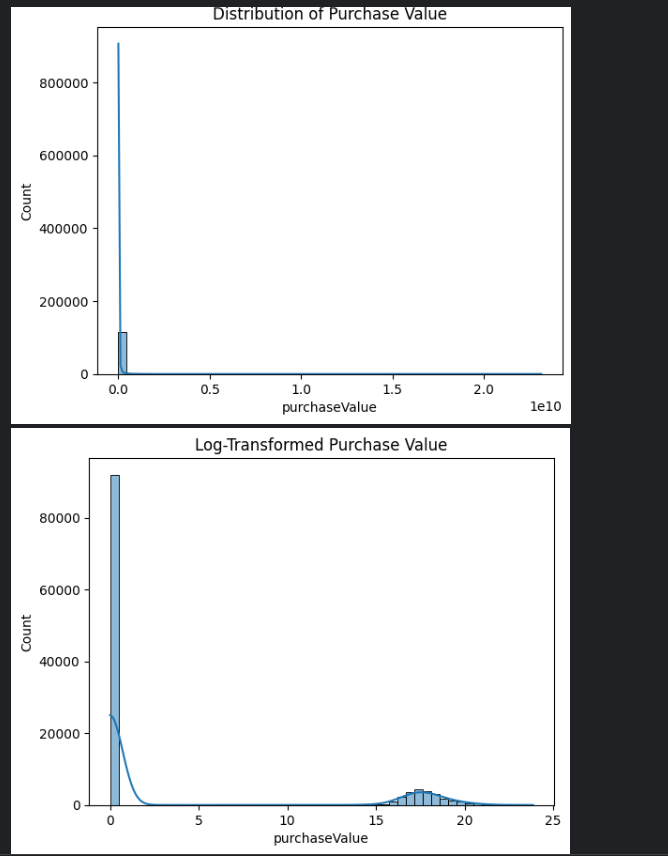

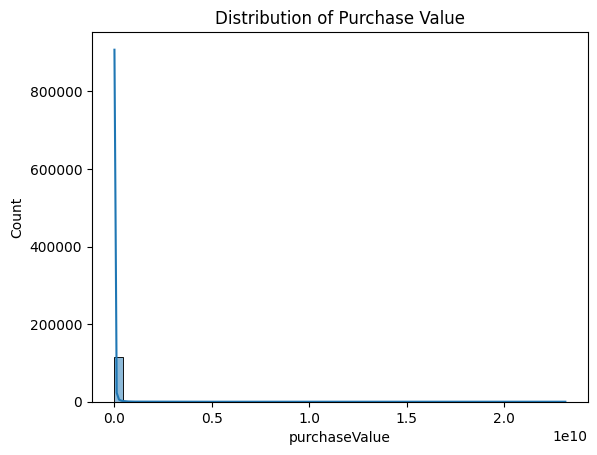

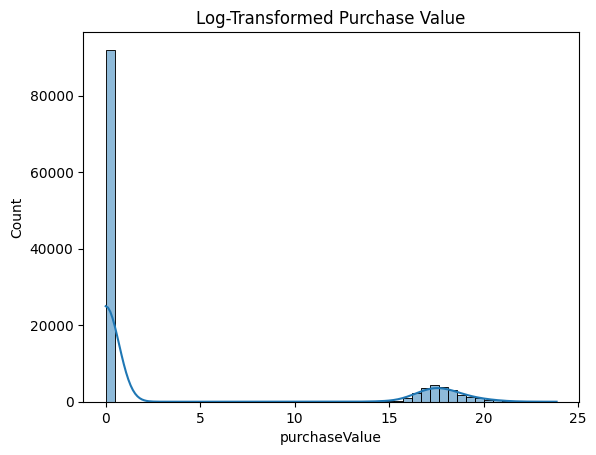

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['purchaseValue'], kde=True, bins=50)
plt.title("Distribution of Purchase Value")
plt.show()

# Log-transform if highly skewed
sns.histplot(np.log1p(df['purchaseValue']), kde=True, bins=50)
plt.title("Log-Transformed Purchase Value")
plt.show()


# [pageViews, totalHits] vs purchaseValue
- Both features have dense clustering around lower values, with only a few outliers causing extreme purchaseValue.
- there might be the possibility that visiters are visiting the pages but not buying.

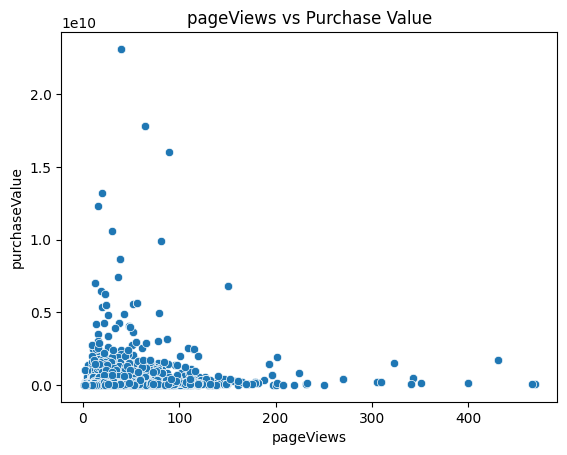

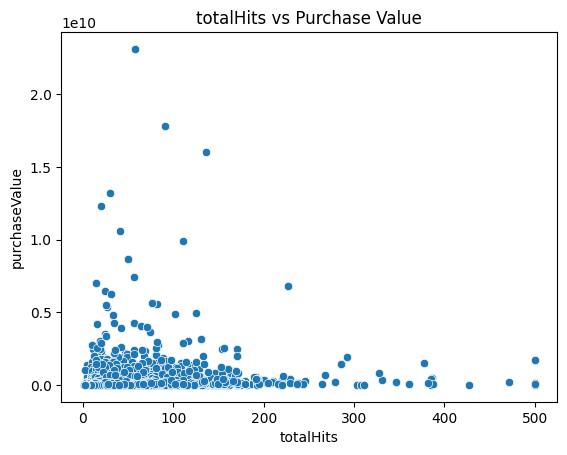

In [10]:
features = ['pageViews', 'totalHits']

for col in features:
    sns.scatterplot(x=col, y='purchaseValue', data=df)
    plt.title(f"{col} vs Purchase Value")
    plt.show()


# Average purchaseValue vs [DeviceType, Continent]
- desktop contribute the highest average purchaseValue far more than mobile and tablet
- Desktop is a high-value segment – possibly more serious buyers or business users
- Americas dominate with the highest average purchase value.

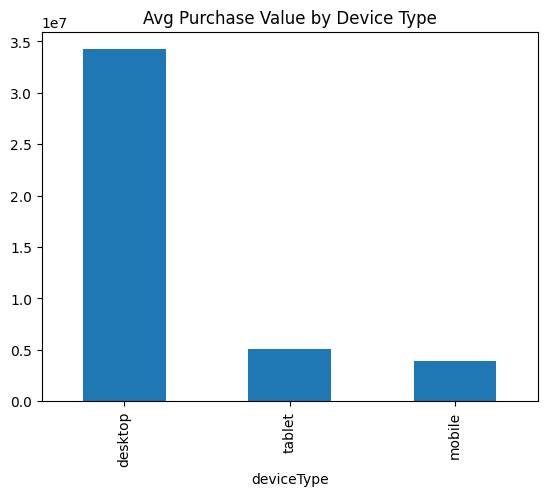

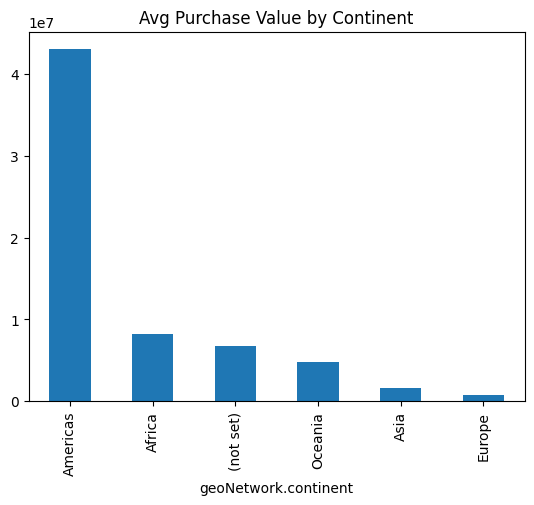

In [11]:
df.groupby('deviceType')['purchaseValue'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title("Avg Purchase Value by Device Type")
plt.show()

df.groupby('geoNetwork.continent')['purchaseValue'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title("Avg Purchase Value by Continent")
plt.show()


# PurchaseValue vs [ DeviceType , UserChannel ]
- Desktop users have the highest and widest spread of purchase values, with many extreme outliers.
- For desktop, the presence of outliers suggests some very high-value purchases, possibly inflating the mean seen earlier.
- Most channels (e.g., Social, Paid Search, Organic Search) show highly skewed distributions with many low purchase values and a few large outliers.
- Direct and Display channels have the most extreme outliers (high purchase values).



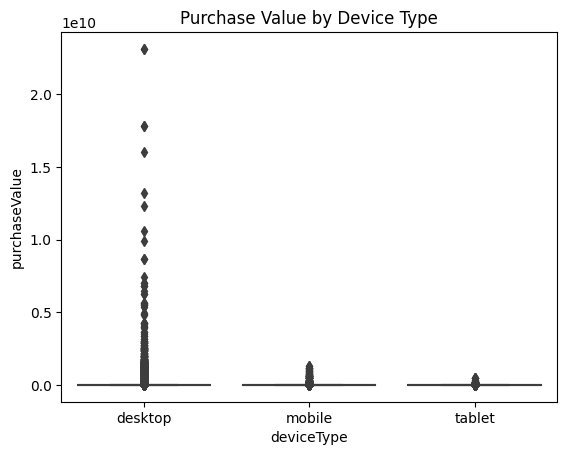

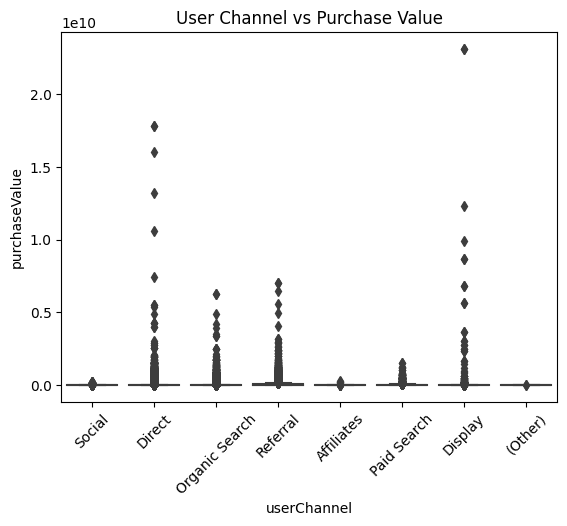

In [12]:
sns.boxplot(x='deviceType', y='purchaseValue', data=df)
plt.title("Purchase Value by Device Type")
plt.show()

sns.boxplot(x='userChannel', y='purchaseValue', data=df)
plt.title("User Channel vs Purchase Value")
plt.xticks(rotation=45)
plt.show()


# Log(PurchaseValue) vs [ deviceType, trafficSource.medium, geoNetwork.continent ]
- Heavy-tailed distribution is visible even after log transformation—many outliers exist.
- Desktop users show a higher median and wider spread of log purchase values compared to mobile or tablet users.
- Channels like (none) and cpm have higher medians and more variability in purchase values.
- Referral, affiliate, and cpc channels have relatively low and concentrated purchase values.
- High variability in (not set) and (none) categories could suggest uncategorized or default sources.
- Americas show the highest log purchase values, both in median and upper spread.
- Other continents like Europe, Asia, and Africa show near-zero median values (even after log), suggesting low engagement or conversions.

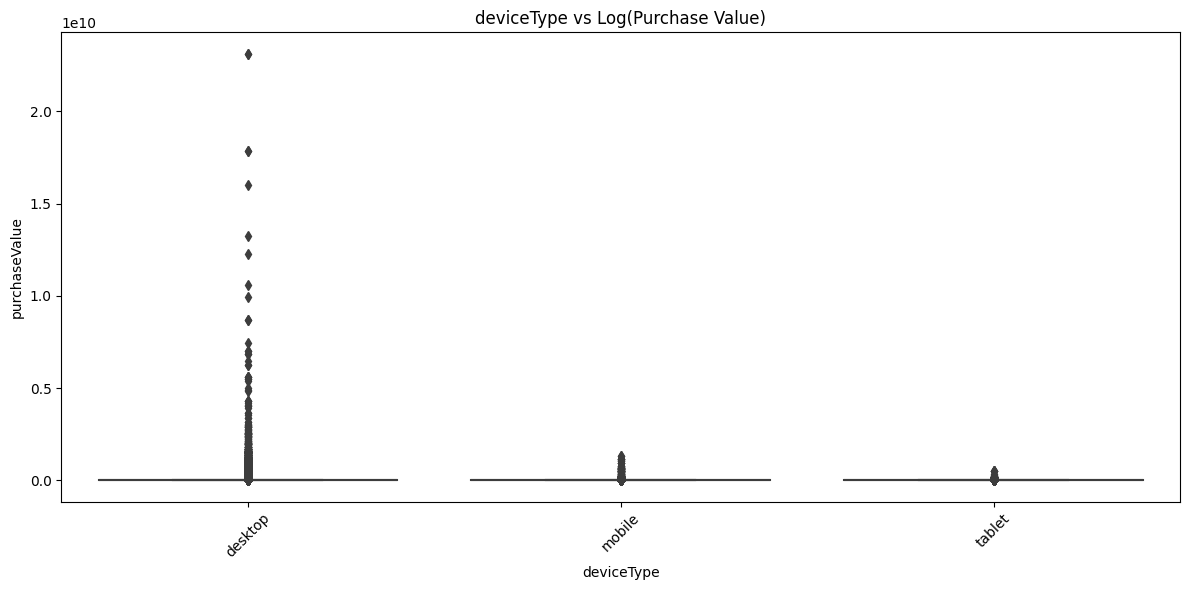

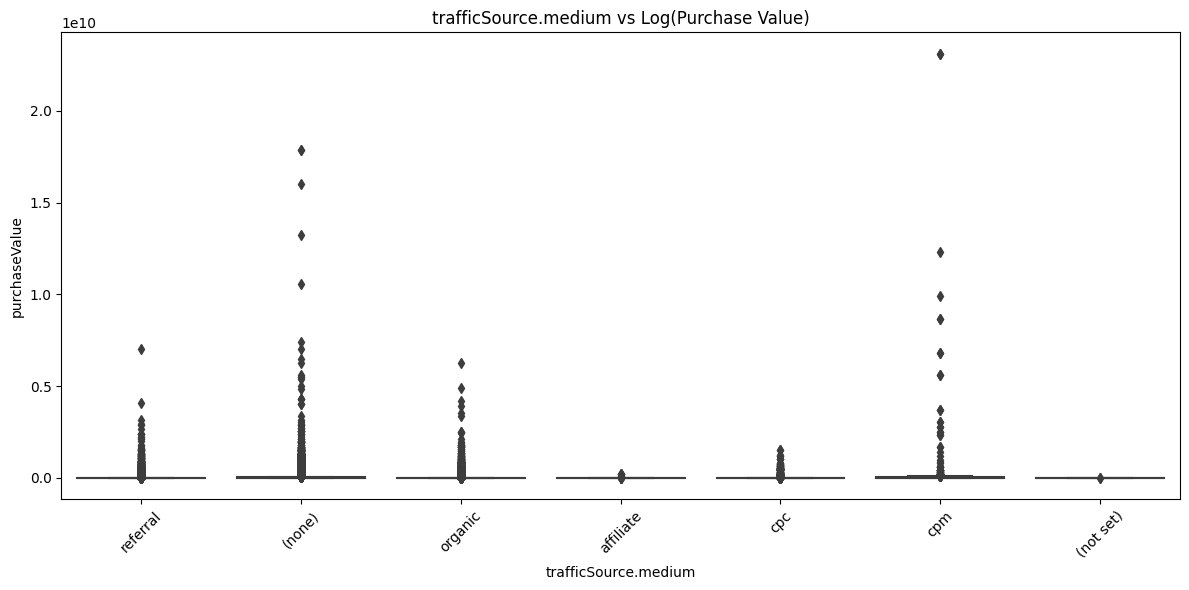

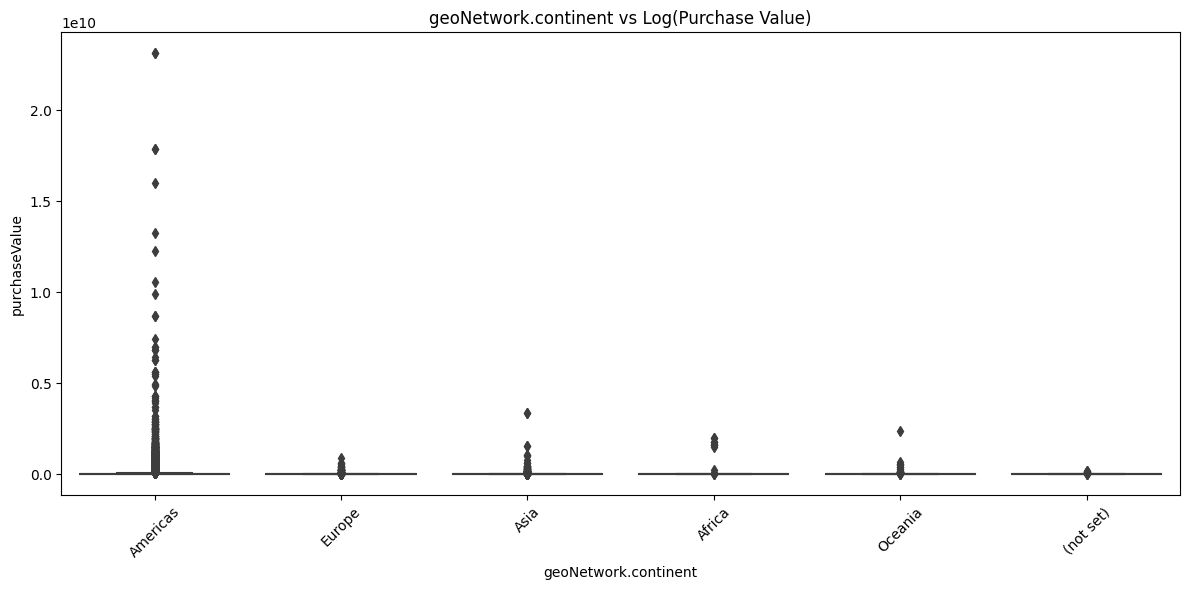

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

categorical_cols = ['deviceType', 'trafficSource.medium', 'geoNetwork.continent'] 

for col in categorical_cols:
    plt.figure(figsize=(12, 6))
    sns.boxplot(x=col, y='purchaseValue', data=df)
    plt.xticks(rotation=45)
    plt.title(f"{col} vs Log(Purchase Value)")
    plt.tight_layout()
    plt.show()



In [14]:
df.columns

Index(['trafficSource.isTrueDirect', 'purchaseValue', 'browser',
       'device.screenResolution', 'trafficSource.adContent',
       'trafficSource.keyword', 'screenSize', 'geoCluster',
       'trafficSource.adwordsClickInfo.slot', 'device.mobileDeviceBranding',
       'device.mobileInputSelector', 'userId', 'trafficSource.campaign',
       'device.mobileDeviceMarketingName', 'geoNetwork.networkDomain',
       'gclIdPresent', 'device.operatingSystemVersion', 'sessionNumber',
       'device.flashVersion', 'geoNetwork.region', 'trafficSource',
       'totals.visits', 'geoNetwork.networkLocation', 'sessionId', 'os',
       'geoNetwork.subContinent', 'trafficSource.medium',
       'trafficSource.adwordsClickInfo.isVideoAd', 'browserMajor',
       'locationCountry', 'device.browserSize',
       'trafficSource.adwordsClickInfo.adNetworkType', 'socialEngagementType',
       'geoNetwork.city', 'trafficSource.adwordsClickInfo.page',
       'geoNetwork.metro', 'pageViews', 'locationZone',
      

In [15]:
df.shape

(116023, 52)

# Identification of duplicates and handling
from duplicated().sum() we found 236 duplicate rows in train dataset they may result in conflict or noise so we should drop those rows.

In [16]:
df.duplicated().sum()

236

In [17]:
df.duplicated().sum()
df=df.drop_duplicates().reset_index(drop=True)


In [18]:
df.shape

(115787, 52)

# Identification of missing values 

In [19]:
train_null= df.isnull().sum().sort_values(ascending=False)
train_null= train_null[train_null>0]

train_null_percent=df.isnull().sum().sort_values(ascending=False)/ df.shape[0] * 100
train_null_percent= train_null_percent[train_null_percent>0]

In [20]:
null_summary = pd.DataFrame({
    'Column': train_null.index,
    'Null Count': train_null.values,
    'Null %': train_null_percent.values
})
null_summary     #  DataFrame of nulls of train dataset

,Column,Null Count,Null %
0,trafficSource.adContent,112826,97.442718
1,trafficSource.adwordsClickInfo.isVideoAd,111518,96.313058
2,trafficSource.adwordsClickInfo.page,111518,96.313058
3,trafficSource.adwordsClickInfo.adNetworkType,111518,96.313058
4,trafficSource.adwordsClickInfo.slot,111518,96.313058
5,trafficSource.referralPath,73099,63.132303
6,trafficSource.isTrueDirect,73050,63.089984
7,trafficSource.keyword,71729,61.949096
8,totals.bounces,68666,59.303721
9,new_visits,35392,30.566471


In [21]:
test_null =test.isnull().sum().sort_values(ascending=False)
test_null=test_null[test_null>0]

test_null_percent= test.isnull().sum().sort_values(ascending=False)/ test.shape[0] * 100
test_null_percent=test_null_percent[test_null_percent>0]

In [22]:
null_summary2 = pd.DataFrame({
    'Column': test_null.index,
    'Null Count': test_null.values,
    'Null %': test_null_percent.values
})

null_summary2  # DataFrame of null of test dataset

,Column,Null Count,Null %
0,trafficSource.adContent,28247,97.383300
1,trafficSource.adwordsClickInfo.adNetworkType,27899,96.183548
2,trafficSource.adwordsClickInfo.isVideoAd,27899,96.183548
3,trafficSource.adwordsClickInfo.page,27899,96.183548
4,trafficSource.adwordsClickInfo.slot,27899,96.183548
5,trafficSource.referralPath,18395,63.417914
6,trafficSource.isTrueDirect,18245,62.900779
7,trafficSource.keyword,17962,61.925119
8,totals.bounces,17274,59.553196
9,new_visits,8912,30.724678


Features with more than 70 percent of null should be drop ...since they have significant number of missing values and their imputation could lead to large noise. Also feature with single unique value should be dropped because they won't contribute much in prediction as for all they are same.

In [23]:
null_threshold= 70
df_nullies= df.isnull().sum()/df.shape[0]* 100
df_droppies= df_nullies[df_nullies> null_threshold ].index.tolist()   # more than 70 percent missing values features
print(f"Dropped {len(df_droppies)} columns due to >{null_threshold}% missing values:")
print(df_droppies)


Dropped 5 columns due to >70% missing values:
['trafficSource.adContent', 'trafficSource.adwordsClickInfo.slot', 'trafficSource.adwordsClickInfo.isVideoAd', 'trafficSource.adwordsClickInfo.adNetworkType', 'trafficSource.adwordsClickInfo.page']


In [24]:
df.drop(columns=df_droppies, inplace=True)
test.drop(columns=df_droppies, inplace=True)

In [25]:
df.shape, test.shape

((115787, 47), (29006, 46))

In [26]:
for i in df.columns:
    print(f" {i} HAS {df[i].nunique()} ")    # number of unique values for the features 

 trafficSource.isTrueDirect HAS 1 
 purchaseValue HAS 6766 
 browser HAS 34 
 device.screenResolution HAS 1 
 trafficSource.keyword HAS 566 
 screenSize HAS 1 
 geoCluster HAS 5 
 device.mobileDeviceBranding HAS 1 
 device.mobileInputSelector HAS 1 
 userId HAS 100499 
 trafficSource.campaign HAS 28 
 device.mobileDeviceMarketingName HAS 1 
 geoNetwork.networkDomain HAS 3 
 gclIdPresent HAS 2 
 device.operatingSystemVersion HAS 1 
 sessionNumber HAS 230 
 device.flashVersion HAS 1 
 geoNetwork.region HAS 388 
 trafficSource HAS 161 
 totals.visits HAS 1 
 geoNetwork.networkLocation HAS 1 
 sessionId HAS 107379 
 os HAS 18 
 geoNetwork.subContinent HAS 23 
 trafficSource.medium HAS 7 
 browserMajor HAS 1 
 locationCountry HAS 193 
 device.browserSize HAS 1 
 socialEngagementType HAS 1 
 geoNetwork.city HAS 695 
 geoNetwork.metro HAS 104 
 pageViews HAS 175 
 locationZone HAS 1 
 device.mobileDeviceModel HAS 1 
 trafficSource.referralPath HAS 941 
 totals.bounces HAS 1 
 date HAS 638 
 d

### Dropped the columns with large number of missing values, with the only values like "not available in demo dataset" , with only one unique value

In [27]:
dropped_cols=[]
for i in df.columns:
    if (df[i].nunique())==1:    # if  number of unique value is 1 then put that feature in dropped_cols list and drop from the train dataset
        print(f" {i} HAS {df[i].nunique()} ") 
        df.drop(columns=i, inplace=True)
        dropped_cols.append(i)

print(dropped_cols)

 trafficSource.isTrueDirect HAS 1 
 device.screenResolution HAS 1 
 screenSize HAS 1 
 device.mobileDeviceBranding HAS 1 
 device.mobileInputSelector HAS 1 
 device.mobileDeviceMarketingName HAS 1 
 device.operatingSystemVersion HAS 1 
 device.flashVersion HAS 1 
 totals.visits HAS 1 
 geoNetwork.networkLocation HAS 1 
 browserMajor HAS 1 
 device.browserSize HAS 1 
 socialEngagementType HAS 1 
 locationZone HAS 1 
 device.mobileDeviceModel HAS 1 
 totals.bounces HAS 1 
 device.language HAS 1 
 device.browserVersion HAS 1 
 device.screenColors HAS 1 
 new_visits HAS 1 
['trafficSource.isTrueDirect', 'device.screenResolution', 'screenSize', 'device.mobileDeviceBranding', 'device.mobileInputSelector', 'device.mobileDeviceMarketingName', 'device.operatingSystemVersion', 'device.flashVersion', 'totals.visits', 'geoNetwork.networkLocation', 'browserMajor', 'device.browserSize', 'socialEngagementType', 'locationZone', 'device.mobileDeviceModel', 'totals.bounces', 'device.language', 'device.b

In [28]:
test.drop(columns=dropped_cols, inplace=True)  # Features of dropped_cols list needs to be deleted from test dataset also

The shape of test and train datasets after dropping the features with only one unique value

In [29]:
df.shape, test.shape

((115787, 27), (29006, 26))

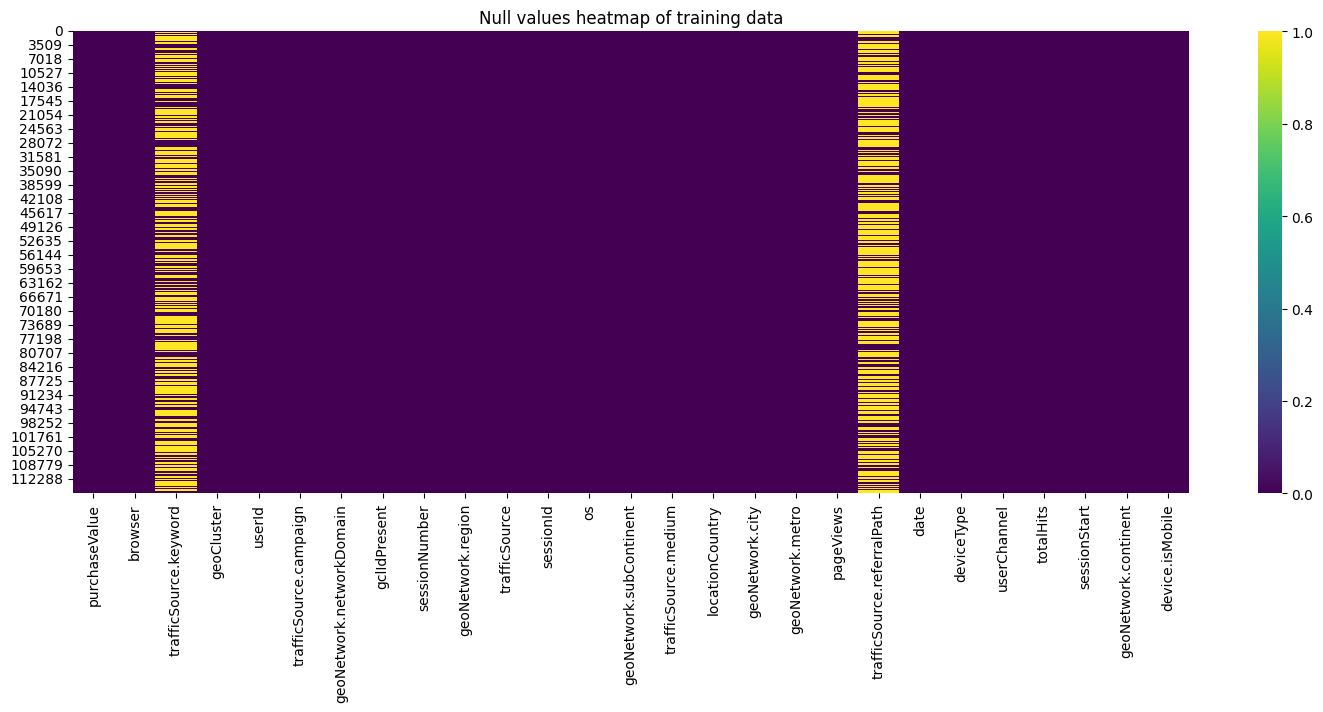

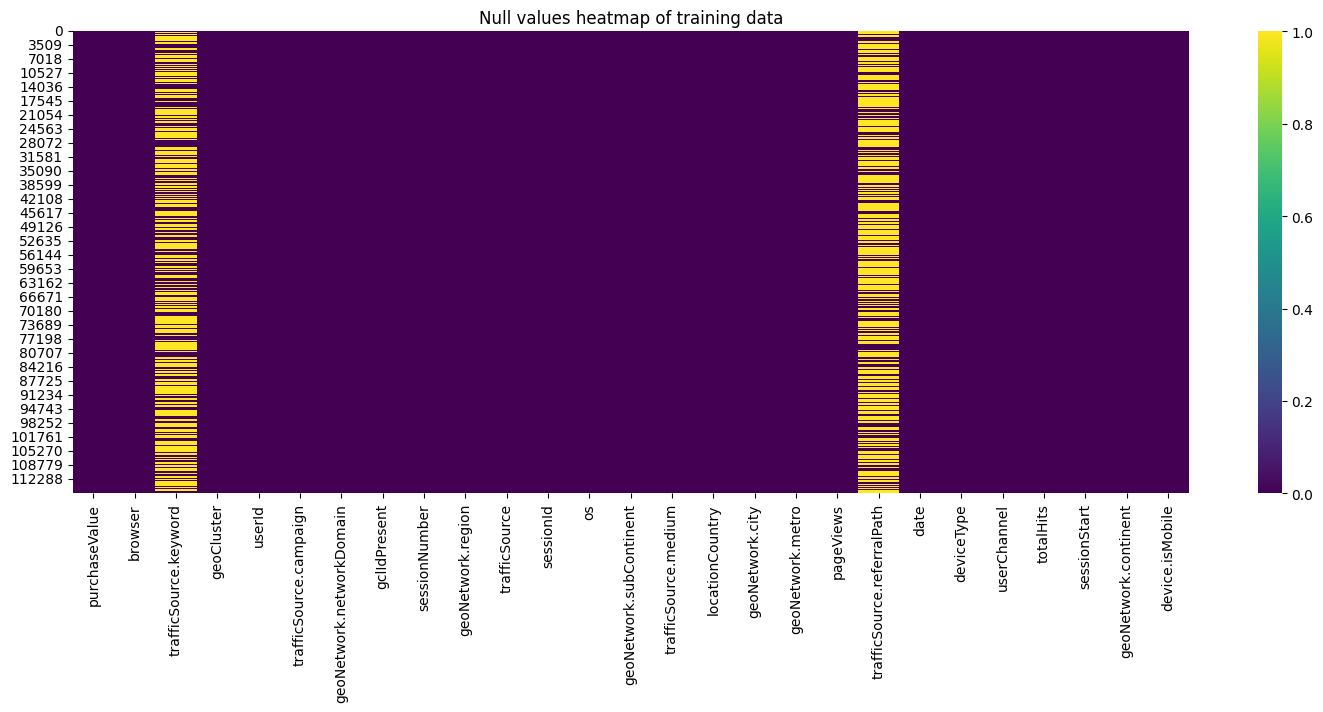

In [30]:
# checking the nulls after dropping out some features

plt.figure(figsize=(18,6))
sns.heatmap(df.isnull(), cmap='viridis')
plt.title("Null values heatmap of training data")
plt.show()

plt.figure(figsize=(18,6))
sns.heatmap(df.isnull(), cmap='viridis')
plt.title("Null values heatmap of training data")
plt.show()

In [31]:
missed_less_70={}
for col, val in (df.isnull().sum().sort_values(ascending=False)/df.shape[0] *100).items():
    if val> 0:
        missed_less_70[col]=val

print(f' missed_less_70 = {missed_less_70}')   # storing features in a dict which has null less 70 percent

 missed_less_70 = {'trafficSource.referralPath': 63.13230328102464, 'trafficSource.keyword': 61.949096185236684, 'pageViews': 0.006909238515550105}


In [32]:
for i in missed_less_70:
    print(f' {i} has  {df[i].nunique()} no. of unique values')  # checking cardinality of less than 70 percent null features

 trafficSource.referralPath has  941 no. of unique values
 trafficSource.keyword has  566 no. of unique values
 pageViews has  175 no. of unique values


we'll impute values in these feature later

# Correlation heatmap
- It shows there are features like ``` totalHits ``` and ```pageViews``` are higly correlated (0.99)
- ```sessionId, date and sessionStart``` are also higly correlated (0.91)
- features like ```sessionNumber, pageViews and totalHits``` are moderately correlated with the purchaseValue( 0.23-0.25)

we can remove one from highly correlated feature to remove the redundancy. Feature that are moderately correlated could be useful but not alone.

Clearly, the correaltion gets improved with the log of target feature as it is highly skewed.

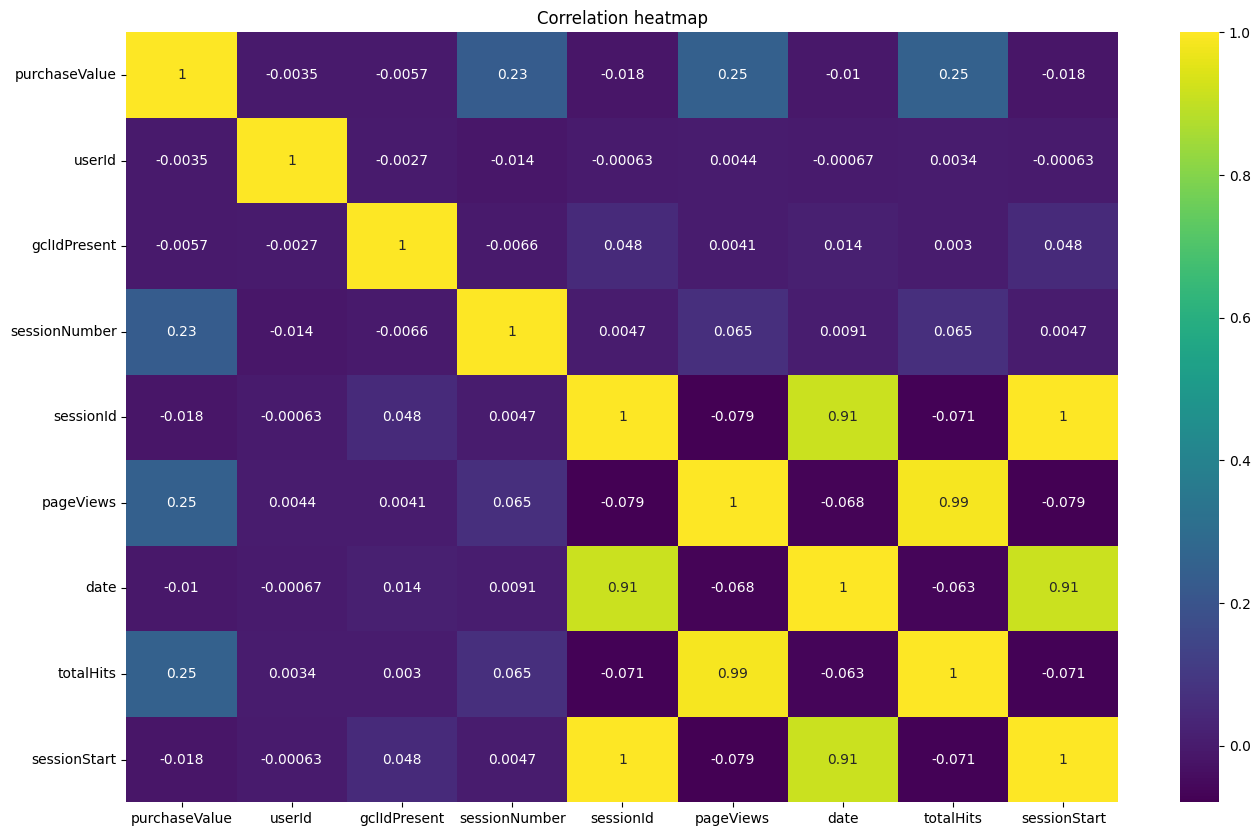

In [33]:
nums= df.select_dtypes(include='number')
plt.figure(figsize=(16,10))
sns.heatmap(nums.corr(), cmap='viridis', annot=True)
plt.title('Correlation heatmap')
plt.show()

In [34]:
df.shape, test.shape

((115787, 27), (29006, 26))

# Feature Engineering 

feature engineering on the highly correlated features to see the impact on model performance 

features generated are 
* ['days_active' , 'hits_per_page', 'hits_per_session', 'page_per_session']


In [35]:
def add_custom_features(df):
    if 'sessionId' in df.columns:
        df = df.drop(columns=['sessionId'])

    # Ensure sessionStart is in datetime
    if 'sessionStart' in df.columns:
        df['sessionStart_dt'] = pd.to_datetime(df['sessionStart'], unit='s', errors='coerce')
    else:
        df['sessionStart_dt'] = pd.NaT

    # Ensure date is parsed correctly 
    if 'date' in df.columns and np.issubdtype(df['date'].dtype, np.number):
        df['date_dt'] = pd.to_datetime(df['date'].astype(str), format='%Y%m%d', errors='coerce')
    elif 'date' in df.columns:
        df['date_dt'] = pd.to_datetime(df['date'], errors='coerce')
    else:
        df['date_dt'] = pd.NaT

    # Difference between sessionStart and date 
    df['days_active'] = (df['sessionStart_dt'] - df['date_dt']).dt.total_seconds() / 86400
    df['days_active'] = df['days_active'].fillna(0)

    # Ratio features
    if 'totalHits' in df.columns and 'pageViews' in df.columns:
        df['hits_per_page'] = (df['totalHits'] / (df['pageViews'] + 1)).fillna(0)

    if 'totalHits' in df.columns and 'sessionNumber' in df.columns:
        df['hits_per_session'] = (df['totalHits'] / (df['sessionNumber'] + 1)).fillna(0)

    if 'pageViews' in df.columns and 'sessionNumber' in df.columns:
        df['page_per_session'] = (df['pageViews'] / (df['sessionNumber'] + 1)).fillna(0)

    # Drop intermediate datetime columns
    df = df.drop(columns=['sessionStart_dt', 'date_dt'], errors='ignore')
    return df



df = add_custom_features(df)
test = add_custom_features(test)


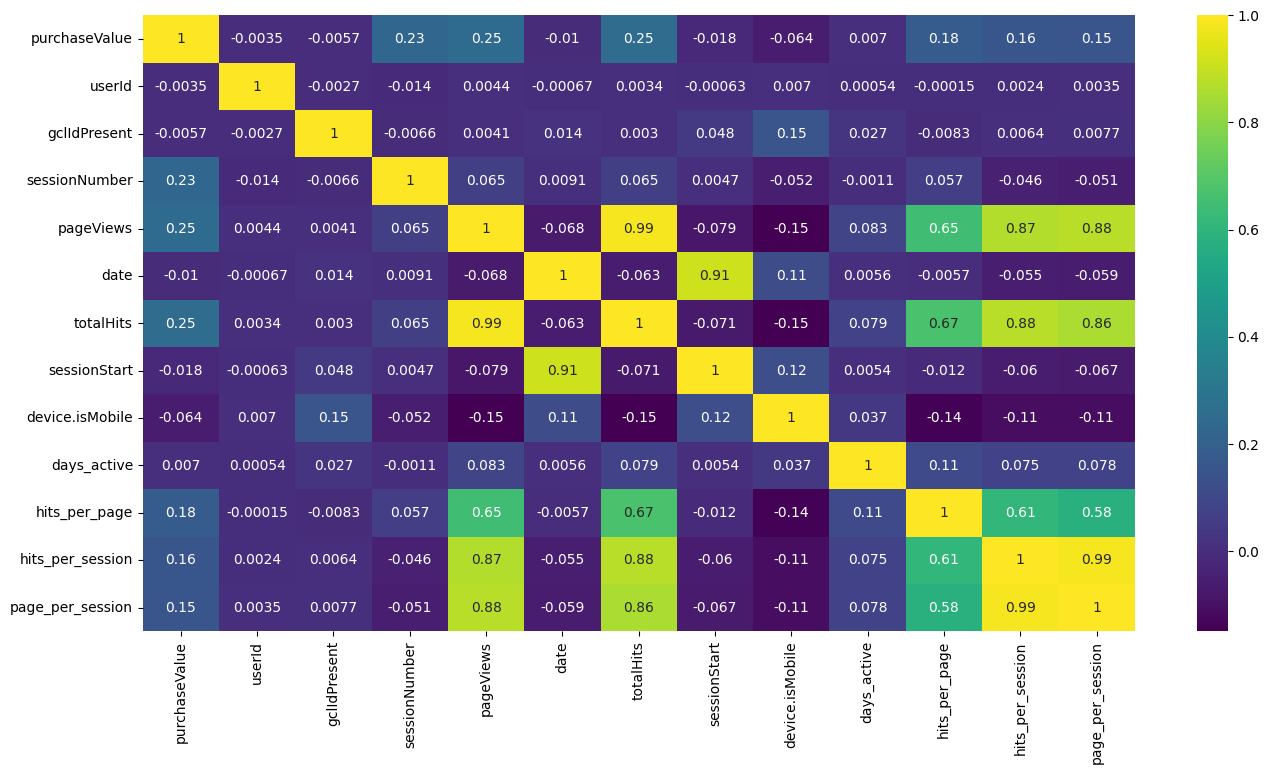

In [36]:
plt.figure(figsize=(16,8))
sns.heatmap(df.corr(numeric_only=True), cmap='viridis', annot=True)
plt.show()

# correlation check for newly generated feature - clearly can see  all 3 have comparatively higher correlation with purchaseValue after pageViews, totalHits and sessionNumber


In [37]:
df

,purchaseValue,browser,trafficSource.keyword,geoCluster,userId,trafficSource.campaign,geoNetwork.networkDomain,gclIdPresent,sessionNumber,geoNetwork.region,...,deviceType,userChannel,totalHits,sessionStart,geoNetwork.continent,device.isMobile,days_active,hits_per_page,hits_per_session,page_per_session
0,0.0,Edge,NaN,Region_2,61421,(not set),domain1,0,1,Washington,...,desktop,Social,1,1500100799,Americas,False,1.277766,0.500000,0.500000,0.500000
1,0.0,Chrome,NaN,Region_3,72287,(not set),domain3,0,1,California,...,desktop,Direct,1,1495262065,Americas,False,1.273900,0.500000,0.500000,0.500000
2,0.0,Chrome,(not provided),Region_2,25180,(not set),domain1,0,2,Lombardy,...,desktop,Organic Search,6,1508510328,Europe,False,0.610278,0.857143,2.000000,2.000000
3,0.0,Internet Explorer,NaN,Region_4,41295,(not set),domain3,0,1,not available in demo dataset,...,desktop,Social,1,1483431838,Asia,False,0.349977,0.500000,0.500000,0.500000
4,88950000.0,Chrome,NaN,Region_3,113697,(not set),domain1,0,1,not available in demo dataset,...,desktop,Direct,66,1475804633,Americas,False,1.072141,1.200000,33.000000,27.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115782,35180000.0,Chrome,NaN,Region_3,109014,(not set),domain1,0,1,New York,...,desktop,Referral,28,1500318402,Americas,False,0.796319,1.037037,14.000000,13.000000
115783,0.0,Chrome,NaN,Region_5,66111,(not set),domain2,0,1,California,...,desktop,Direct,1,1478624150,Americas,False,0.705440,0.500000,0.500000,0.500000
115784,0.0,Chrome,NaN,Region_1,97614,(not set),domain2,0,2,Delhi,...,desktop,Referral,1,1470384216,Asia,False,0.335833,0.500000,0.333333,0.333333
115785,0.0,Chrome,(not provided),Region_5,71050,(not set),domain1,0,1,Tennessee,...,desktop,Organic Search,2,1506953297,Americas,False,0.589086,0.666667,1.000000,1.000000


In [38]:
df.shape , test.shape

((115787, 30), (29006, 29))

In [39]:
num_cols=df.select_dtypes(include='number').columns.drop('purchaseValue')  
cat_cols=df.select_dtypes(include='object').columns

# Outliers
Since the number of outliers are too much and removing could be risky. So the safest approach is to keep them and tuned Tree Based models.

 outliers in userId  are 0
 outliers in gclIdPresent  are 4283


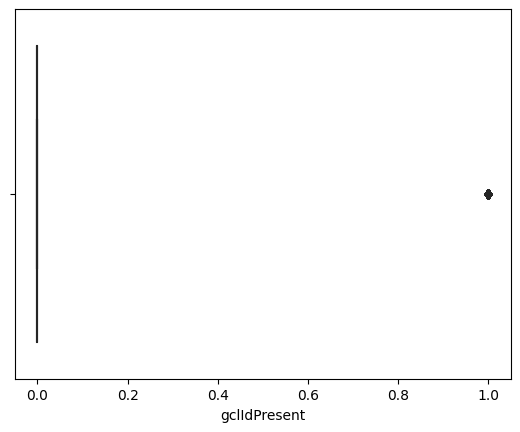

 outliers in sessionNumber  are 14071


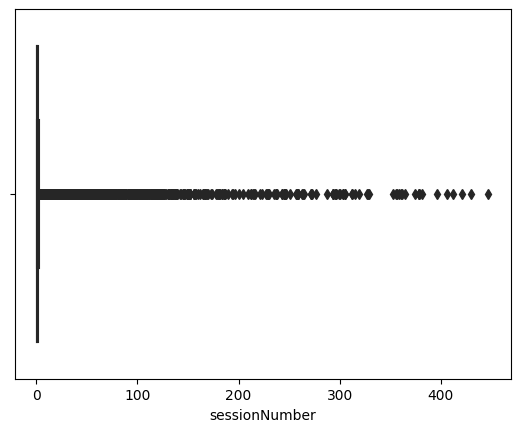

 outliers in pageViews  are 12329


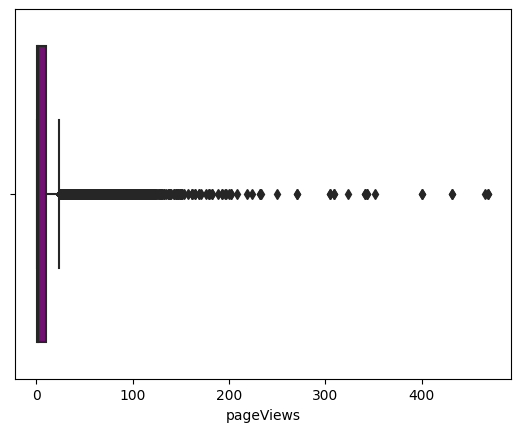

 outliers in date  are 0
 outliers in totalHits  are 13061


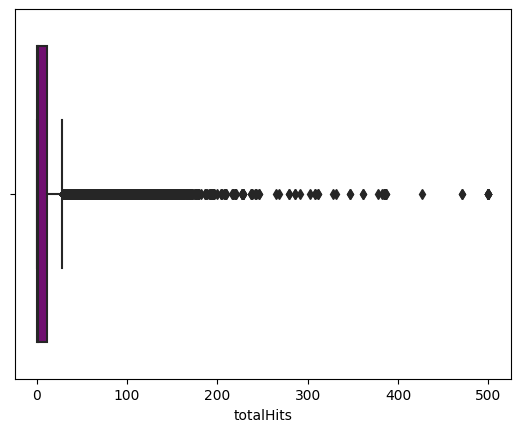

 outliers in sessionStart  are 0
 outliers in days_active  are 0
 outliers in hits_per_page  are 403


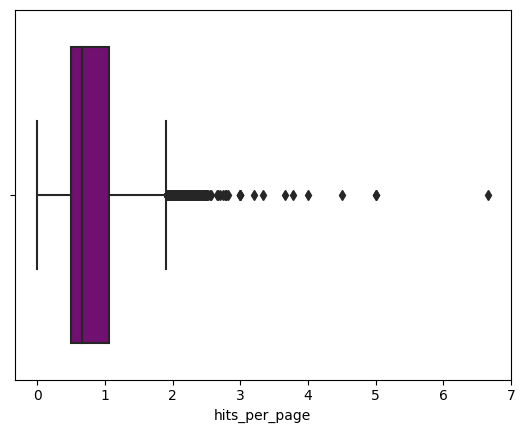

 outliers in hits_per_session  are 13996


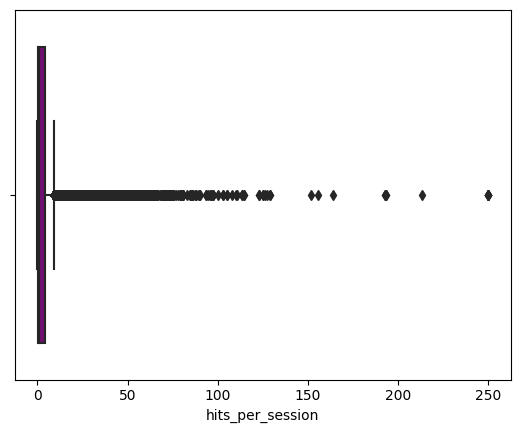

 outliers in page_per_session  are 13404


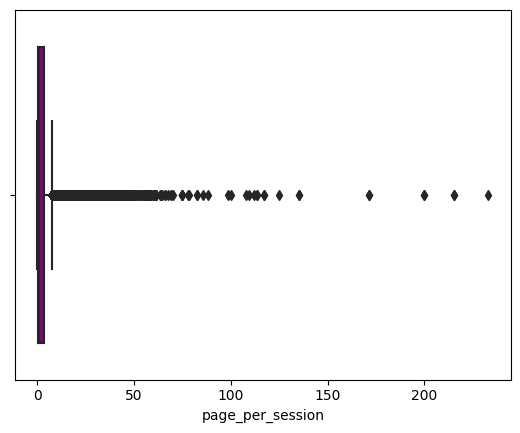

In [40]:
def outliers_iqr(df, col):
    Q1= df[col].quantile(0.25)
    Q3= df[col].quantile(0.75)
    iqr= Q3-Q1
    upper= Q3 + 1.5*iqr
    lower= Q1 - 1.5*iqr
    return df[(df[col]> upper) | (df[col]< lower)]


for col in num_cols:
    print(f" outliers in {col}  are {outliers_iqr(df, col).shape[0]}")
    if outliers_iqr(df, col).shape[0] >0:
        sns.boxplot(x=df[col], color='purple')
        plt.show()

# Distribution of ['page_per_session', 'hits_per_session', 'totalHits', 'pageViews']

- All the four features are highly skewed.
- Most values are lower left concentrated auggests the majority of users interact with only a few pages or hits per session.

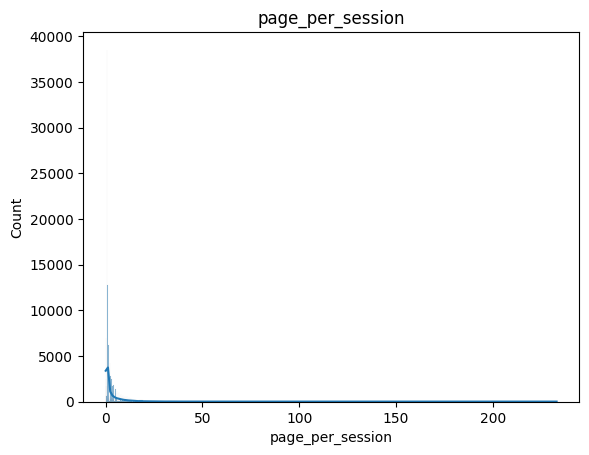

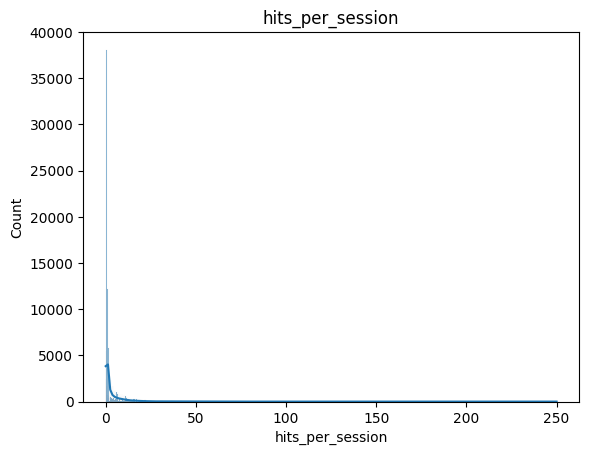

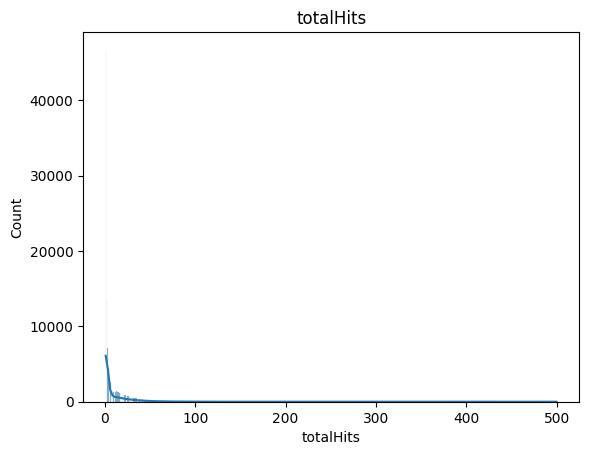

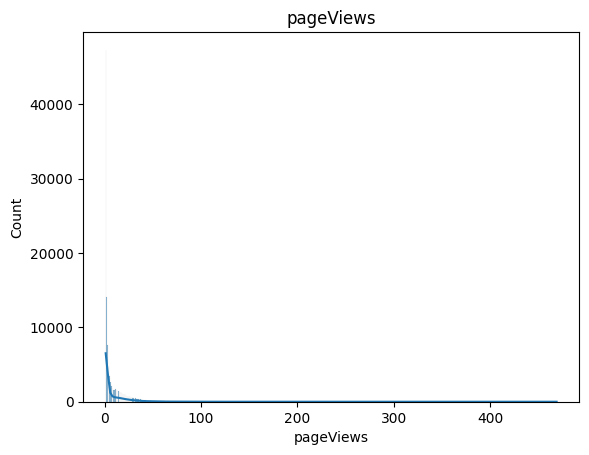

In [41]:
for col in ['page_per_session', 'hits_per_session', 'totalHits', 'pageViews']:
    sns.histplot((df[col]), kde=True)
    plt.title(f'{col}')
    plt.show()


In [42]:
ohe_cols=[]
tg_cols=[]
for i in df.columns:
    if (df[i].nunique())<10:
       ohe_cols.append(i)
    else:
        tg_cols.append(i)
print(f'ohe_cols = {ohe_cols}')
print(f' tg_cols = {tg_cols}')

ohe_cols = ['geoCluster', 'geoNetwork.networkDomain', 'gclIdPresent', 'trafficSource.medium', 'deviceType', 'userChannel', 'geoNetwork.continent', 'device.isMobile']
 tg_cols = ['purchaseValue', 'browser', 'trafficSource.keyword', 'userId', 'trafficSource.campaign', 'sessionNumber', 'geoNetwork.region', 'trafficSource', 'os', 'geoNetwork.subContinent', 'locationCountry', 'geoNetwork.city', 'geoNetwork.metro', 'pageViews', 'trafficSource.referralPath', 'date', 'totalHits', 'sessionStart', 'days_active', 'hits_per_page', 'hits_per_session', 'page_per_session']


In [43]:
X=df.drop(columns='purchaseValue')
y=df.purchaseValue

ohe_cols = ['geoCluster', 'geoNetwork.networkDomain', 'gclIdPresent', 'trafficSource.medium',
            'deviceType', 'userChannel',  'geoNetwork.continent', 'device.isMobile']


tg_cols = [ 'browser', 'trafficSource.keyword', 'userId', 'trafficSource.campaign', 'sessionNumber',
           'geoNetwork.region', 'trafficSource', 'os', 'geoNetwork.subContinent', 'locationCountry', 
           'geoNetwork.city', 'geoNetwork.metro', 'pageViews', 'trafficSource.referralPath', 'date', 
           'totalHits', 'sessionStart', 'days_active', 'hits_per_page', 'hits_per_session', 'page_per_session']

low_card_cols = [col for col in ohe_cols ]
high_card_cols=[ col for col in tg_cols]


numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

low_card_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

high_card_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_enc', TargetEncoder())   
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('low_card', low_card_pipe, low_card_cols),
    ('high_card', high_card_pipe, high_card_cols)
], remainder='drop')




X_enco=preprocessor.fit_transform(X, y)
test_enco=preprocessor.transform(test)



In [44]:
df.shape, test.shape

((115787, 30), (29006, 29))

In [45]:
X_enco=X_enco
y=df.purchaseValue

X_train, X_test, y_train , y_test = train_test_split(X_enco,y, test_size=0.2, random_state=42 )

In [46]:
X_enco.shape, X_train.shape, X_test.shape, test_enco.shape, df.shape


((115787, 60), (92629, 60), (23158, 60), (29006, 60), (115787, 30))

# Important Insights & Findings from the Dataset
1. Target Variable Distribution
    - purchaseValue is highly right-skewed.
    - Most users spend low amounts or most of values are close to zero, while a few have very high spending, suggesting outliers or VIP shoppers.


2. User Activity & Engagement
 Features like hits, pageViews, and sessionCount show:
    - More active users (higher pageViews/hits) tend to spend more.
    - However, some high-activity users still have zero purchase, indicating window shoppers or comparison behavior.


3. Session-Based Behavior
 Engineered features such as:
    - ```hits_per_page = hits / pageViews ``` ```pages_per_session = pageViews / sessionCount``` reveal user efficiency or focus.


4. Categorical Variables Influence
 Encoded features like deviceCategory, channelGrouping, trafficSource, and browser reveal:

   - Users from organic search and referral traffic show higher average purchases than those from direct sources.
   - gclIdPresent = 1 (users who came through Google Ads) have a notably higher average purchaseValue, confirming ad conversion value.


5. High-Cardinality Feature Handling
  Features like keyword, source, and referralPath had thousands of unique values.
   - Using target encoding helped reduce dimensionality while retaining useful signals.
   - Some specific keywords/sources showed very high mean purchase values, possibly due to high-intent users.


6. Missing Data Patterns
   - Several features had significant missing values, e.g., keyword, referralPath, adContent.
   - Missingness was non-random:
       - Missing keyword often corresponds to direct visits (low purchase).
       - Missing adContent aligns with organic traffic (variable outcomes).


# Baseline Models

In [47]:
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(),
    'RandomForest': RandomForestRegressor(random_state=42),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'XGBoost': XGBRegressor(random_state=42),
    'LightGBM': LGBMRegressor( random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42)
}

# Store predictions and models
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = y_pred


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018232 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5322
[LightGBM] [Info] Number of data points in the train set: 92629, number of used features: 59
[LightGBM] [Info] Start training from score 26057253.639702


In [48]:
from sklearn.metrics import r2_score

r2_scores = {}
for name, y_pred in results.items():
    r2 = r2_score(y_test, y_pred)
    r2_scores[name] = r2
    print(f"{name} R2: {r2:.4f}")
    


LinearRegression R2: 0.9984
Ridge R2: 0.9984
RandomForest R2: 0.9987
GradientBoosting R2: 0.9932
KNN R2: 0.8764
XGBoost R2: 0.9666
LightGBM R2: 0.7049
AdaBoost R2: 0.9557


# Hyperparameter Tuning of RandomForestRegressor

In [49]:
rf_model= RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)

rf_param_dist = {
    'n_estimators': randint(200, 600), 
    'max_depth': randint(6, 20),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 6),
    'max_features': ['sqrt', 'log2', 0.8]
}

rf_search = RandomizedSearchCV(
    rf_model,
    param_distributions=rf_param_dist,
    n_iter=10,
    scoring='r2',
    cv=3,
    random_state=RANDOM_STATE,
    verbose=1,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)
print("Best RF CV R2:", rf_search.best_score_)
print("Best RF Params:")
print(rf_search.best_params_)
rf_best = rf_search.best_estimator_
rf_best

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best RF CV R2: 0.9467392518049912
Best RF Params:
{'max_depth': 10, 'max_features': 0.8, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 414}


RandomForestRegressor(max_depth=10, max_features=0.8, min_samples_leaf=2,
                      min_samples_split=4, n_estimators=414, n_jobs=-1,
                      random_state=42)

# Hyperparameter tuning of AdaBoostRegressor


In [50]:
ada_model = AdaBoostRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),random_state=RANDOM_STATE)

ada_param_dist = {
    'n_estimators': randint(100, 400),             
    'learning_rate': uniform(0.01, 0.3),           
    'estimator__max_depth': randint(2, 6),   
    'estimator__min_samples_split': randint(2, 10),
    'estimator__min_samples_leaf': randint(1, 5)
}


ada_search = RandomizedSearchCV(
    ada_model,
    param_distributions=ada_param_dist,
    n_iter=20,             
    scoring='r2',
    cv=3,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1
)


ada_search.fit(X_train, y_train)
print("Best AdaBoost CV R2:", ada_search.best_score_)
print("Best AdaBoost Params:", ada_search.best_params_)
ada_best = ada_search.best_estimator_
ada_best

Best AdaBoost CV R2: 0.9744811220095168
Best AdaBoost Params: {'estimator__max_depth': 5, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 7, 'learning_rate': 0.1075990992289793, 'n_estimators': 307}


AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=5,
                                                  min_samples_split=7,
                                                  random_state=42),
                  learning_rate=0.1075990992289793, n_estimators=307,
                  random_state=42)

# Hyperparameter Tuning of GradientBoostingRegressor

In [51]:
gbr_model = GradientBoostingRegressor( random_state=RANDOM_STATE)

gbr_param_dist = {
    'n_estimators': randint(200, 500),
    'learning_rate': loguniform(0.01, 0.15),
    'max_depth': randint(2, 6),
    'min_samples_leaf': randint(1, 10),
    'subsample': uniform(0.7, 0.3)  
}
 
gbr_search = RandomizedSearchCV(
    gbr_model,
    param_distributions=gbr_param_dist,
    n_iter=15,
    scoring='r2',
    cv=3,
    random_state=RANDOM_STATE,
    verbose=1,
    n_jobs=-1
)

gbr_search.fit(X_train, y_train)
print("Best GBR CV R2:", gbr_search.best_score_)
print("Best GBR Params:")
print(gbr_search.best_params_)
gbr_best = gbr_search.best_estimator_
gbr_best

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best GBR CV R2: 0.9760885253334295
Best GBR Params:
{'learning_rate': 0.02413338039141455, 'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 252, 'subsample': 0.8760253496991544}


GradientBoostingRegressor(learning_rate=0.02413338039141455, max_depth=5,
                          min_samples_leaf=2, n_estimators=252, random_state=42,
                          subsample=0.8760253496991544)

# Hyperparameter tuning of XGBRegressor

In [52]:
xgb_model=XGBRegressor( random_state=RANDOM_STATE)

group=df['userId'].iloc[:X_train.shape[0]]

xgb_param_dist = {
    'n_estimators': randint(600, 1200),
    'learning_rate': loguniform(0.01, 0.08),
    'max_depth': randint(6, 9),
    'min_child_weight': randint(1, 5),
    'subsample': uniform(0.7, 0.3),
    'colsample_bytree': uniform(0.6, 0.4),
    'gamma': uniform(0.3, 2.5),
    'reg_alpha': loguniform(1e-3, 2),
    'reg_lambda': loguniform(1e-3, 5)
}

gkf = GroupKFold(n_splits=5)


xgb_search = RandomizedSearchCV(
    xgb_model,
    param_distributions=xgb_param_dist,
    n_iter=20,
    scoring='r2',
    cv=gkf.split(X_train, y_train, groups=group),
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)
print("Best XGB CV R2:", xgb_search.best_score_)
print("Best XGB Params:")
print(xgb_search.best_params_)
xgb_best = xgb_search.best_estimator_
xgb_best


Best XGB CV R2: 0.8676595074637478
Best XGB Params:
{'colsample_bytree': 0.8918424713352255, 'gamma': 1.893893678388033, 'learning_rate': 0.0632751151469228, 'max_depth': 6, 'min_child_weight': 3, 'n_estimators': 1061, 'reg_alpha': 0.6342931154488703, 'reg_lambda': 0.467364638603794, 'subsample': 0.7707954759246867}


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8918424713352255, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=1.893893678388033,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.0632751151469228,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=3, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1061, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

# Hyperparameter tuning of LGBMRegressor

In [53]:
lgbm_model =  LGBMRegressor( verbose=-1, random_state=RANDOM_STATE, n_jobs=-1)

lgbm_param_dist = {
    'n_estimators': randint(500, 1500),
    'learning_rate': loguniform(0.01, 0.15),
    'num_leaves': randint(20, 150),
    'max_depth': randint(1, 12),  
    'min_child_samples': randint(5, 100),
    'subsample': uniform(0.6, 0.4),      
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': loguniform(1e-5, 5),
    'reg_lambda': loguniform(1e-5, 5)
}

lgbm_search = RandomizedSearchCV(
    lgbm_model,
    param_distributions=lgbm_param_dist,
    n_iter=15,
    scoring='r2',
    cv=3,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1
)

lgbm_search.fit(X_train, y_train)
print("Best LGBM CV R2:", lgbm_search.best_score_)
print("Best LGBM Params:")
print(lgbm_search.best_params_)
lgbm_best = lgbm_search.best_estimator_
lgbm_best

Best LGBM CV R2: 0.8305220084579709
Best LGBM Params:
{'colsample_bytree': 0.878206434570451, 'learning_rate': 0.014583659157547245, 'max_depth': 7, 'min_child_samples': 19, 'n_estimators': 670, 'num_leaves': 48, 'reg_alpha': 0.00020133249808196874, 'reg_lambda': 2.7460358140803138e-05, 'subsample': 0.7159005811655073}


LGBMRegressor(colsample_bytree=0.878206434570451,
              learning_rate=0.014583659157547245, max_depth=7,
              min_child_samples=19, n_estimators=670, n_jobs=-1, num_leaves=48,
              random_state=42, reg_alpha=0.00020133249808196874,
              reg_lambda=2.7460358140803138e-05, subsample=0.7159005811655073,
              verbose=-1)

# Comparisons 
1. Baseline R² Scores (Before Tuning)

| Model             | R² Score |
|-------------------|----------|
| LinearRegression  | 0.9984   |
| Ridge             | 0.9984   |
| RandomForest      | 0.9987   |
| GradientBoosting  | 0.9932   |
| KNN               | 0.8764   |
| XGBoost           | 0.9666   |
| LightGBM          | 0.7049   |
| AdaBoost          | 0.9557   |

The Linear models perform exceptionally well indicating overfitting.
KNN is generally sensitive to scaling and high dimensionality.
LightGBM’s default parameters likely didn’t suit the data distribution.


## 2. After Tuning

| Model | R² Score | Validation Score Analysis | Public Score |
|---|---:|---|---:|
| Random Forest | 0.9467 | Solid performance, with a slight drop from the baseline due to cross-validation averaging. The model benefits from deeper trees and a higher number of estimators. | ~0.54 |
| AdaBoost | 0.9745 | Very good validation performance. Tuning the underlying `DecisionTreeRegressor` significantly improved the model's performance. | ~0.40 |
| Gradient Boosting | 0.9761 | Highest cross-validated R² score. The optimal learning rate and subsampling ratio provided a strong balance between bias and variance. | ~0.28 |
| XGBoost | 0.8677 | Significant drop in validation performance, potentially due to regularization and aggressive hyperparameter settings, such as high `gamma` and low `reg_lambda`. However, it performed comparatively better on the public leaderboard. | ~0.68 |
| LightGBM | 0.8305 | Relatively poor validation performance, possibly due to overfitting, sensitivity to feature distributions, or suboptimal hyperparameter settings. Further feature preprocessing and tuning may help. | ~0.45 |
3. insights
   * GradientBoosting, AdaBoost, RandomForest
     - CV R²: Very High (~0.95–0.97)
     - But poor public scores (~0.28–0.54) suggest:
     - Likely overfitting on training data despite tuning
     - Models captured dataset-specific patterns but failed to generalize
  * XGBoost
    - Lower CV R² (0.8677) than others, yet best public score (~0.68)
    - Implies strong generalization capability, despite being slightly underfit on training
    - Regularization (gamma, lambda) may have helped to prevent overfitting slightly.
 * LightGBM
   - Performed worst both in CV (0.83) and public score (~0.44)
   - Likely sensitive to preprocessing, encoding, or imbalanced feature influence

4. Overall Findings
   - CV performance alone isn't enough — always validate with public datasets.
   - Overfitting is a real risk with high-capacity models like GradientBoosting/AdaBoost.
   - XGBoost’s regularization made it more resilient to data shifts and improved public leaderboard results.
   - Model tuning must balance both R² and real-world generalization, not just optimize CV.


In [54]:

best_model = xgb_search

test_predictions = best_model.predict(test_enco)

sample_submission = pd.read_csv('/kaggle/input/engage-2-value-from-clicks-to-conversions/sample_submission.csv')

submission = pd.DataFrame({
    'id': sample_submission['ID'],
    'purchaseValue': test_predictions
})

submission.to_csv('submission.csv', index=False)

print("saved successfully!")

saved successfully!


In [55]:
submission.shape


(29006, 2)

#  Ideas Learnt from the Dataset and/or Models

 ### From the Dataset
1. User Behavior is Highly Diverse
   - A significant portion of users do not purchase anything, while a few spend disproportionately high amounts.
   - This behavior leads to a skewed target distribution and high outliers because of which the linear models didn't perform well on validation set. They get overfitting on the training data since in notebook they are giving too high score but in public score leading too low like 0.13 etc.
2. High-Engagement ≠ High Purchase (Always)
   - Although higher pageViews, hits, and sessionCount generally indicate more purchase activity, some highly engaged users do not convert.
   - Indicates non-linear relationships between behavior and conversion, suitable for tree-based models.

3. Categorical Features Are Informative But Tricky
   - Variables like useChannel, medium, and deviceType etc. hold predictive power.
   - Target encoding were essential to handle high-cardinality features.


### From the Models
1. Tree-Based Models Outperform Linear Models
    - Models like Random Forest, Gradient Boosting, and XGBoost outperformed Linear Regression and Ridge due to their ability to:
          -> Capture non-linear patterns
          -> Handle feature interactions
          -> Be robust to outliers

2. Hyperparameter Tuning Gives Significant Gains
    - Models tuned via RandomizedSearchCV showed better R² scores and generalization compared to defaults on validation to reduce overfitting.
    - Even small parameter tweaks (like max_depth, n_estimators, learning_rate) made notable improvements(from 0.64 to 0.67).
3. Overfitting Risk 
    - Some models like linear models and tree models like RandomForest had very high training R² (~0.99+), but slight drops on test set and on public score it dropped too much.



